# Preparar el entorno

In [1]:
pip install opencv-python numpy matplotlib scikit-learn

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Cargar y procesar la imagen

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression


# Cargar imagen
imagen = cv2.imread("persona.jpg")

# Convertir imagen de BGR a RGB
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# Convertir imagen a HSV
imagen_hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)

# Separar color rojo
rojo1 = cv2.inRange(imagen_hsv, (0, 100, 50), (10, 255, 255))
rojo2 = cv2.inRange(imagen_hsv, (170, 100, 50), (180, 255, 255))

mascara_roja = cv2.bitwise_or(rojo1, rojo2)

# Separar colores blancos y grises
mascara_blanca_gris = cv2.inRange(
    imagen_hsv,
    (0, 0, 60),
    (180, 50, 255)
)

# Calcular cantidad de píxeles
total = imagen.shape[0] * imagen.shape[1]

cantidad_rojo = cv2.countNonZero(mascara_roja)
cantidad_blanco_gris = cv2.countNonZero(mascara_blanca_gris)

# Calcular proporciones
proporcion_rojo = cantidad_rojo / total
proporcion_blanco_gris = cantidad_blanco_gris / total

print("Proporción de rojo:", proporcion_rojo)
print("Proporción de blanco/gris:", proporcion_blanco_gris)

Proporción de rojo: 0.014047046703296703
Proporción de blanco/gris: 0.9851631181318682


# Visualizar la separación de colores

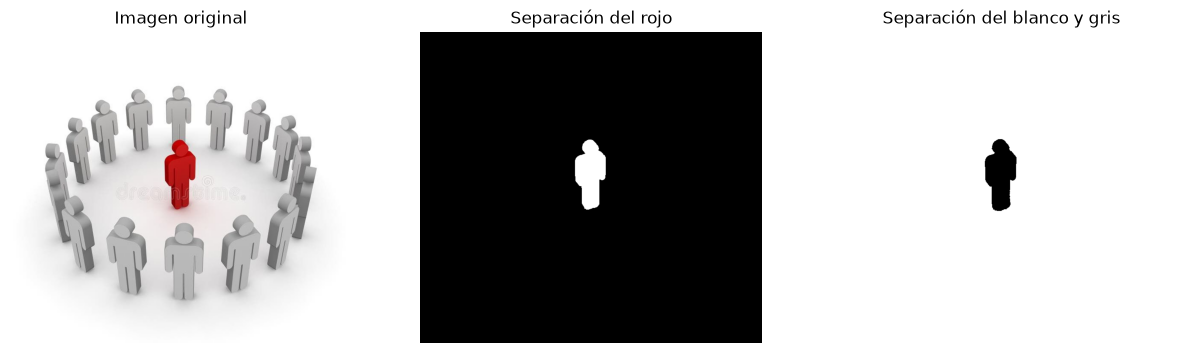

In [14]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen_rgb)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mascara_roja, cmap="gray")
plt.title("Separación del rojo")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mascara_blanca_gris, cmap="gray")
plt.title("Separación del blanco y gris")
plt.axis("off")

plt.show()

# Visualizar la distribución de colores

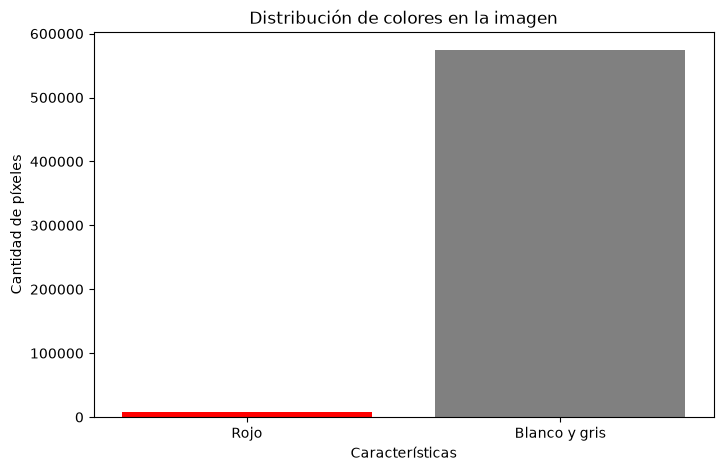

Espacio de características:
[[0.01404705 0.98516312]]


In [15]:
colores = ["Rojo", "Blanco y gris"]
cantidades = [cantidad_rojo, cantidad_blanco_gris]

plt.figure(figsize=(8, 5))

plt.bar(colores, cantidades, color=["red", "gray"])

plt.title("Distribución de colores en la imagen")
plt.ylabel("Cantidad de píxeles")
plt.xlabel("Características")

plt.show()

X = np.array([
    [proporcion_rojo, proporcion_blanco_gris]
])

print("Espacio de características:")
print(X)

# Entrenar un clasificador

In [16]:
# Datos de entrenamiento simulados
X_entrenamiento = np.array([
    [0.70, 0.20],
    [0.65, 0.25],
    [0.80, 0.10],
    [0.10, 0.75],
    [0.15, 0.70],
    [0.20, 0.65]
])

# 1 = persona roja, 0 = personas blancas/grises
y = np.array([1, 1, 1, 0, 0, 0])

# Crear y entrenar clasificador
modelo = LogisticRegression()
modelo.fit(X_entrenamiento, y)

# Clasificar imagen analizada
prediccion = modelo.predict(X)

print("Predicción:", prediccion)
print("Clase:", "Rojo" if prediccion[0] == 1 else "Blanco/gris")

Predicción: [0]
Clase: Blanco/gris
